# **CCB01. Quality control and annotation transfer across *Cyclospora cayetanensis* strain assemblies.**

**Date**: Oct 10, 2026

**TL;DR**
- **Goal**: Establish a high-quality, non-redundant working set of CCay genome assemblies and transfer reference annotations onto each one.
- **Problem**: Only one CCay assembly carries a full annotation, assembly quality varies widely across submissions, and the public set contains duplicate BioSamples and suppressed records. Apparent "variability" in a gene could just as easily be missing coverage, a contig break, or a truncated gene model.
- **Solution**: Filter assemblies on completeness with `compleasm`, resolve duplicates and suppressed entries, characterize population structure with `sourmash` alongside geography and collection date, and lift the CcayRef3 annotation onto every surviving assembly with `Liftoff`.

---

**Project context**

A rapid antigen test needs a target that is both invariant across strains and physically accessible to a capture antibody. Across CCB01–05 the ideal target is defined as the intersection of three independent filters:

1. **Conserved** across strains, by pi_N/pi_S (CCB05)
2. **Surface-accessible**, by subcellular localization and topology (CCB02)
3. **Abundant** enough to detect in an oocyst preparation (CCB03)

This notebook produces the genomic substrate for filter 1.

---

**Resources used**:

- [NCBI Datasets](https://www.ncbi.nlm.nih.gov/datasets/genome/?taxon=88456), *C. cayetanensis* genome assemblies
  - O'Leary NA, Cox E, Holmes JB, et al. Exploring and retrieving sequence and metadata for species across the tree of life with NCBI Datasets. Sci Data. 2024 Jul 5;11(1):732. doi: 10.1038/s41597-024-03571-y. PMID: 38969627; PMCID: PMC11226681.
- [compleasm](https://academic.oup.com/bioinformatics/article/39/10/btad595/7284108)
  - Huang N, Li H. compleasm: a faster and more accurate reimplementation of BUSCO. Bioinformatics. 2023;39(10):btad595. doi: 10.1093/bioinformatics/btad595
- [sourmash](https://sourmash.readthedocs.io/)
  - Brown CT, Irber L. sourmash: a library for MinHash sketching of DNA. JOSS. 2016;1(5):27. doi: 10.21105/joss.00027
- [Liftoff](https://github.com/agshumate/Liftoff)
  - Shumate A, Salzberg SL. Liftoff: accurate mapping of gene annotations. Bioinformatics. 2021;37(12):1639-1643. doi: 10.1093/bioinformatics/btaa1016

In [ ]:
import os
import gc
import re
import json
import glob
import shutil
import subprocess
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path
from tqdm.notebook import tqdm
from google.colab import drive
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import squareform

**Mounting Google Drive to ensure output from runs persist across executions.**

In [ ]:
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
! curl -o datasets 'https://ftp.ncbi.nlm.nih.gov/pub/datasets/command-line/v2/linux-amd64/datasets'
! curl -o dataformat 'https://ftp.ncbi.nlm.nih.gov/pub/datasets/command-line/v2/linux-amd64/dataformat'
! chmod +x datasets datasets
! chmod +x datasets dataformat

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 19.6M  100 19.6M    0     0  5380k      0  0:00:03  0:00:03 --:--:-- 5379k
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 19.1M  100 19.1M    0     0  7559k      0  0:00:02  0:00:02 --:--:-- 7562k


Downloading all datasets typically takes 2-5 minutes.

**This step is only needed if reproducing the analysis from start to finish.**

In [ ]:
! ./datasets download genome taxon 88456  --include all --filename ccay_genomes.zip

In [ ]:
! unzip ccay_genomes.zip

Downloading summary data about the assemblies (also available in the downloaded dataset, but `datasets` offers nice formatting).

In [ ]:
! ./datasets summary genome taxon 88456 --assembly-source all --as-json-lines | ./dataformat tsv genome --fields accession,assminfo-biosample-accession,assminfo-status,assminfo-atypicalwarnings,assmstats-total-sequence-len,assmstats-atgc-count,assmstats-gc-percent,assmstats-number-of-contigs,assmstats-contig-n50,assminfo-bioproject,assminfo-sequencing-tech,assminfo-biosample-strain,assminfo-biosample-isolate,assminfo-biosample-collection-date,assminfo-biosample-geo-loc-name,assminfo-biosample-isolation-source,annotinfo-status,annotinfo-busco-complete,annotinfo-busco-singlecopy,annotinfo-busco-duplicated,annotinfo-busco-fragmented,annotinfo-busco-missing,annotinfo-busco-lineage,annotinfo-busco-totalcount,annotinfo-busco-version,assminfo-biosample-collection-date > ccay_genome_summary.tsv

In [ ]:
ccay_genome_summary = pd.read_csv('ccay_genome_summary.tsv', sep='\t')
ccay_genome_summary

,Assembly Accession,Assembly BioSample Accession,Assembly Status,Assembly Atypical Warnings,Assembly Stats Total Sequence Length,Assembly Stats ATGC Count,Assembly Stats GC Percent,Assembly Stats Number of Contigs,Assembly Stats Contig N50,Assembly BioProject Accession,...,Assembly BioSample Isolation source,Annotation Status,Annotation BUSCO Complete,Annotation BUSCO Single Copy,Annotation BUSCO Duplicated,Annotation BUSCO Fragmented,Annotation BUSCO Missing,Annotation BUSCO Lineage,Annotation BUSCO Total Count,Annotation BUSCO Version
0,GCF_002999335.1,SAMN08618443,current,NaN,44363576,44363576.0,52.0,738,192560,PRJNA357479,...,stool,Full annotation,0.956175,0.952191,0.003984,0.01992,0.023904,coccidia_odb10,502.0,4.0.2
1,GCF_000769155.1,SAMN02944928,suppressed,NaN,44034411,NaN,NaN,3573,43794,PRJNA256967,...,feces,Full annotation,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,GCA_000769155.2,SAMN02944928,current,NaN,44034411,43961175.0,52.0,3573,43794,PRJNA256967,...,feces,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,GCA_001305735.1,SAMN03983352,current,NaN,44527903,44527597.0,52.0,862,187708,PRJNA292682,...,stool,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,GCA_002019455.1,SAMN05982170,current,NaN,42346107,42345051.0,52.0,1307,117049,PRJNA292682,...,feces,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,GCA_002019465.1,SAMN05982179,current,NaN,43895689,43887919.0,52.0,1346,104955,PRJNA292682,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,GCA_002019475.1,SAMN05982165,current,NaN,41397365,41397053.0,52.0,1599,79453,PRJNA292682,...,feces,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,GCA_002019905.1,SAMN05982183,current,NaN,43010379,43009752.0,52.0,1479,94614,PRJNA292682,...,feces,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,GCA_002893305.1,SAMN07337752,current,NaN,44198550,44195887.0,52.0,739,240741,PRJNA316938,...,stool,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,GCA_002893315.1,SAMN07337751,current,NaN,43066541,43064140.0,52.0,2001,50863,PRJNA316938,...,"stool, Traveler to Costa rica",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


We'll drop rows (ignore genome assemblies) where `Assembly Status` is 'suppressed' (for this dataset, this is a previous reference genome which has been replaced) or there are `Assembly Atypical Warnings`


In [ ]:
ccay_genome_summary = ccay_genome_summary[ccay_genome_summary['Assembly Status'] != 'suppressed']
ccay_genome_summary = ccay_genome_summary[ccay_genome_summary['Assembly Atypical Warnings'] != 'contaminated']
ccay_genome_summary.shape

(47, 25)

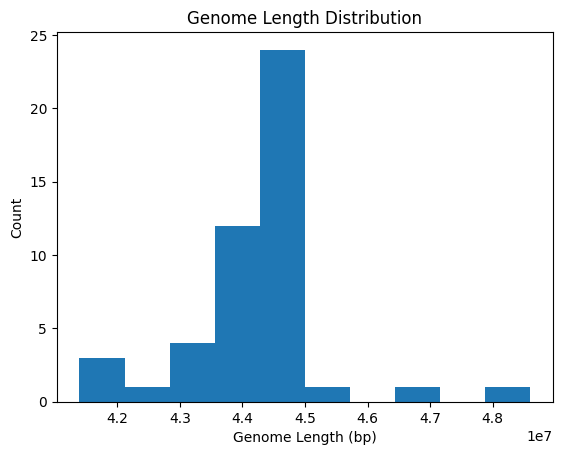

In [ ]:
plt.hist(ccay_genome_summary['Assembly Stats Total Sequence Length'])
plt.xlabel('Genome Length (bp)')
plt.ylabel('Count')
plt.title('Genome Length Distribution')
plt.show()

## **2. Quality control using `compleasm`.**

[`compleasm`](https://github.com/huangnengCSU/compleasm) is a genome completeness assessment tool (a reimplementation of BUSCO) but is much faster. Crucially, it matches BUSCO on accuracy. We'll be using it to discard any poor quality, incomplete genome assemblies.

---

Install the required imports and code for compleasm.

In [ ]:
! pip install biopython
! pip install hmmer
! git clone https://github.com/lh3/miniprot
! cd miniprot && make

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 33.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 42.2 MB/s eta 0:00:00
Cloning into 'miniprot'...
remote: Enumerating objects: 1460, done.
remote: Counting objects: 100% (189/189), done.
remote: Compressing objects: 100% (69/69), done.
remote: Total 1460 (delta 139), reused 129 (delta 120), pack-reused 1271 (from 2)
Receiving objects: 100% (1460/1460), 398.23 KiB | 7.66 MiB/s, done.
Resolving deltas: 100% (1066/1066), done.
gcc -c -std=c99 -g -Wall -O3   kalloc.c -o kalloc.o
gcc -c -std=c99 -g -Wall -O3   kthread.c -o kthread.o
gcc -c -std=c99 -g -Wall -O3   nasw-sse.c -o nasw-sse.o
gcc -c -std=c99 -g -Wall -O3   nasw-tab.c -o nasw-tab.o
gcc -c -std=c99 -g -Wall -O3   sys.c -o sys.o
gcc -c -std=c99 -g -Wall -O3   misc.c -o misc.o
gcc -c -std=c99 -g -Wall -O3   options.c -o options.o
gcc -c -std=c99 -g -Wall -O3   ntseq.c -o ntseq.o
ntseq.c: In function ‘mp_ntseq_restore’:
ntseq.c:184:9: warning: ignoring

In [ ]:
! git clone https://github.com/huangnengCSU/compleasm.git

Cloning into 'compleasm'...
remote: Enumerating objects: 981, done.
remote: Counting objects: 100% (285/285), done.
remote: Compressing objects: 100% (89/89), done.
remote: Total 981 (delta 239), reused 232 (delta 193), pack-reused 696 (from 1)
Receiving objects: 100% (981/981), 220.79 KiB | 4.51 MiB/s, done.
Resolving deltas: 100% (618/618), done.


In [ ]:
INPUT_DIR = "ncbi_dataset/data"

COMPLEASM_OUT = "/content/drive/MyDrive/compleasm_runs"
LOCAL_OUT = "/content/compleasm_tmp"
LIB_DIR   = "/content/drive/MyDrive/compleasm_lineages"
CPU_COUNT = os.cpu_count()

In [ ]:
search_pattern = os.path.join(INPUT_DIR, "*", "*.fna")
fna_files = glob.glob(search_pattern)
fna_files = [f for f in fna_files if "_".join(Path(f).stem.split("_")[:2]) in ccay_genome_summary['Assembly Accession'].values]

print(f"Found {len(fna_files)} genomes.")

Found 0 genomes.


In [ ]:
def is_done(stem):
    return os.path.exists(os.path.join(COMPLEASM_OUT, stem, "DONE"))

def run_compleasm(fna_file, cpu_count):
    stem = Path(fna_file).stem
    local_dir = os.path.join(LOCAL_OUT, stem)
    shutil.rmtree(local_dir, ignore_errors=True)  # clear any partial run

    # coccidia is the BUSCO lineage used by the reference genome assmebly
    cmd = ["python", "/content/compleasm/compleasm.py", "run",
           "-a", fna_file, "-o", local_dir,
           "-l", "coccidia", "--odb", "odb12",
           "-L", LIB_DIR, "-t", str(cpu_count)]
    result = subprocess.run(cmd, capture_output=True, text=True)

    # error handling
    if result.returncode != 0 or not os.path.exists(os.path.join(local_dir, "summary.txt")):
        with open(os.path.join(COMPLEASM_OUT, "failed.log"), "a") as f:
            f.write(f"=== {stem} ===\n{result.stderr[-2000:]}\n")
        print(f"FAILED {stem}")
        return

    dest = os.path.join(COMPLEASM_OUT, stem)
    shutil.rmtree(dest, ignore_errors=True)
    shutil.copytree(local_dir, dest)
    Path(dest, "DONE").touch()
    shutil.rmtree(local_dir)
    print(f"Completed {stem}")

Run compleasm on all eligible `.fna` files.

In [ ]:
todo = [f for f in fna_files if not is_done(Path(f).stem)]
print(f"{len(fna_files) - len(todo)} done, {len(todo)} remaining")

for fna_file in tqdm(todo):
    run_compleasm(fna_file, CPU_COUNT)

0 done, 0 remaining


0it [00:00, ?it/s]

Read in `compleasm` summary data and combine into DataFrame.

In [ ]:
PAT = re.compile(r"^([SDFIM]):([\d.]+)%,\s*(\d+)$|^N:(\d+)$", re.M)
OUT = Path(COMPLEASM_OUT)

def parse(summary: Path) -> dict:
    text = summary.read_text()
    stem = summary.parent.name
    row = {"stem": stem, "accession": "_".join(stem.split("_")[:2])}
    for cat, pct, cnt, n in PAT.findall(text):
        if n:
            row["N"] = int(n)
        else:
            row[f"{cat}_pct"] = float(pct)
            row[f"{cat}_n"] = int(cnt)
    lineage = re.search(r"^## lineage:\s*(\S+)", text, re.M)
    version = re.search(r"^# compleasm version is:\s*(\S+)", text, re.M)
    row["lineage"] = lineage.group(1) if lineage else None
    row["compleasm_version"] = version.group(1) if version else None
    return row

files = sorted(p / "summary.txt" for p in OUT.iterdir()
               if (p / "DONE").exists() and (p / "summary.txt").exists())
df = pd.DataFrame([parse(f) for f in files])
print(len(files), "summaries")

# sanity check against the input list
expected = {Path(f).stem for f in fna_files}
missing = sorted(expected - set(df["stem"]))
print(f"{len(missing)} not finished:", missing)

In [ ]:
df.head()

,stem,accession,S_pct,S_n,D_pct,D_n,F_pct,F_n,I_pct,I_n,M_pct,M_n,N,lineage,compleasm_version
0,GCA_000769155.2_ASM76915v2_genomic,GCA_000769155.2,94.36,435,0.22,1,5.21,24,0.0,0,0.22,1,461,coccidia_odb12,0.2.9
1,GCA_001305735.1_ASM130573v1_genomic,GCA_001305735.1,98.26,453,0.22,1,1.52,7,0.0,0,0.00,0,461,coccidia_odb12,0.2.9
2,GCA_002019455.1_ASM201945v1_genomic,GCA_002019455.1,90.89,419,0.00,0,2.82,13,0.0,0,6.29,29,461,coccidia_odb12,0.2.9
3,GCA_002019465.1_ASM201946v1_genomic,GCA_002019465.1,95.23,439,0.22,1,3.25,15,0.0,0,1.30,6,461,coccidia_odb12,0.2.9
4,GCA_002019475.1_ASM201947v1_genomic,GCA_002019475.1,90.24,416,0.00,0,4.34,20,0.0,0,5.42,25,461,coccidia_odb12,0.2.9


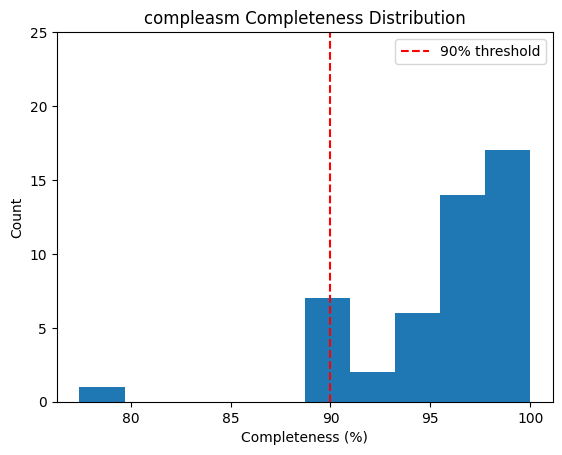

In [ ]:
plt.hist(df['S_pct'])
plt.xlabel('Completeness (%)')
plt.ylabel('Count')
plt.title('compleasm Completeness Distribution')
plt.ylim(0, 25)
plt.vlines(x=90, ymin=0, ymax=45, colors='r', linestyles='dashed', label='90% threshold')
plt.legend()
plt.show()

In [ ]:
df.to_csv('compleasm_summary.tsv', sep='\t')

In [ ]:
ccay_genome_summary = pd.merge(df, ccay_genome_summary, left_on='accession', right_on='Assembly Accession')
ccay_genome_summary.shape

(47, 40)

### **2.1 Filter to >90% completeness.**

In [ ]:
ccay_genome_summary = ccay_genome_summary[ccay_genome_summary['S_pct'] >= 90.00]
ccay_genome_summary.shape

(44, 40)

In [ ]:
# drop the row where stem == GCA_002999335.1_CcayRef3_genomic
ccay_genome_summary = ccay_genome_summary[ccay_genome_summary['stem'] != "GCA_002999335.1_CcayRef3_genomic"]
ccay_genome_summary

,stem,accession,S_pct,S_n,D_pct,D_n,F_pct,F_n,I_pct,I_n,...,Assembly BioSample Isolation source,Annotation Status,Annotation BUSCO Complete,Annotation BUSCO Single Copy,Annotation BUSCO Duplicated,Annotation BUSCO Fragmented,Annotation BUSCO Missing,Annotation BUSCO Lineage,Annotation BUSCO Total Count,Annotation BUSCO Version
0,GCA_000769155.2_ASM76915v2_genomic,GCA_000769155.2,94.36,435,0.22,1,5.21,24,0.00,0,...,feces,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,GCA_001305735.1_ASM130573v1_genomic,GCA_001305735.1,98.26,453,0.22,1,1.52,7,0.00,0,...,stool,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,GCA_002019455.1_ASM201945v1_genomic,GCA_002019455.1,90.89,419,0.00,0,2.82,13,0.00,0,...,feces,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,GCA_002019465.1_ASM201946v1_genomic,GCA_002019465.1,95.23,439,0.22,1,3.25,15,0.00,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,GCA_002019475.1_ASM201947v1_genomic,GCA_002019475.1,90.24,416,0.00,0,4.34,20,0.00,0,...,feces,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,GCA_002019905.1_ASM201990v1_genomic,GCA_002019905.1,93.49,431,0.22,1,3.47,16,0.00,0,...,feces,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,GCA_002893305.1_ASM289330v1_genomic,GCA_002893305.1,99.13,457,0.22,1,0.43,2,0.00,0,...,stool,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,GCA_002893365.1_ASM289336v1_genomic,GCA_002893365.1,91.32,421,0.22,1,4.77,22,0.00,0,...,"stool, related to cilantro consumption",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,GCA_002893405.1_ASM289340v1_genomic,GCA_002893405.1,93.71,432,0.00,0,0.43,2,0.00,0,...,stool,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11,GCA_002893425.1_ASM289342v1_genomic,GCA_002893425.1,100.00,461,0.00,0,0.00,0,0.00,0,...,stool,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## **3. Lineage & clustering with `sourmash`, time, and location.**

Sourmash is a k-mer analysis tool we can use to generate signatures for all our remaining genomes. These can then be compared to get an understanding of how related they are. For this analysis, the goal is to get an understanding of just how similar all of these strains / samples are to each other.



### **3.1 Clustering by Jaccard similarity with sourmash.**

We'll start by installing sourmash.

In [ ]:
! pip install sourmash

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 19.9 MB/s  0:00:00
  Created wheel for screed: filename=screed-1.2.0-py3-none-any.whl size=91791 sha256=c3ba91372d1efecdb0f852a36e0a5ebb97d2a0085a5dec9f2776bebcb76aa97f
  Stored in directory: /root/.cache/pip/wheels/66/8b/a9/559bbe28f89c56c0aaf32f02d665bd66aca8e5f6e90155c8ae
Successfully built screed
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [sourmash]


In [ ]:
hq_fna_files = []

for dir, stem in zip(ccay_genome_summary.accession, ccay_genome_summary.stem):
  hq_fna_files.append(Path(os.path.join(INPUT_DIR, dir, stem + ".fna")))

len(hq_fna_files)

43

Run `sourmash sketch` to get a signature for each genome.

In [ ]:
SIG = Path("/content/drive/MyDrive/sourmash_sigs")
SIG.mkdir(exist_ok=True)

for fna in hq_fna_files:
  out = SIG / f"{fna.stem}.sig"
  if out.exists():
    continue
  subprocess.run([
      'sourmash', 'sketch', 'dna', '-p', 'k=21,k=31,scaled=200', '--name', f'{fna.stem}',
      '--output', f'{out}', f'{fna}'
  ])
print(len(list(SIG.glob('*.sig')))), "signatures"

43


(None, 'signatures')

Use `sourmash compare` to determine the Jaccard similarity between all genomes.

In [ ]:
SIG = Path("/content/drive/MyDrive/sourmash_sigs")

In [ ]:
! sourmash compare {SIG}/*.sig -k 31 --csv /content/ccay_jaccard.csv --ani


== This is sourmash version 4.9.4. ==
== Please cite Irber et. al (2024), doi:10.21105/joss.06830. ==

loaded 43 signatures total.

min similarity in matrix: 0.994


We'll present relatedness as a dendrogram.

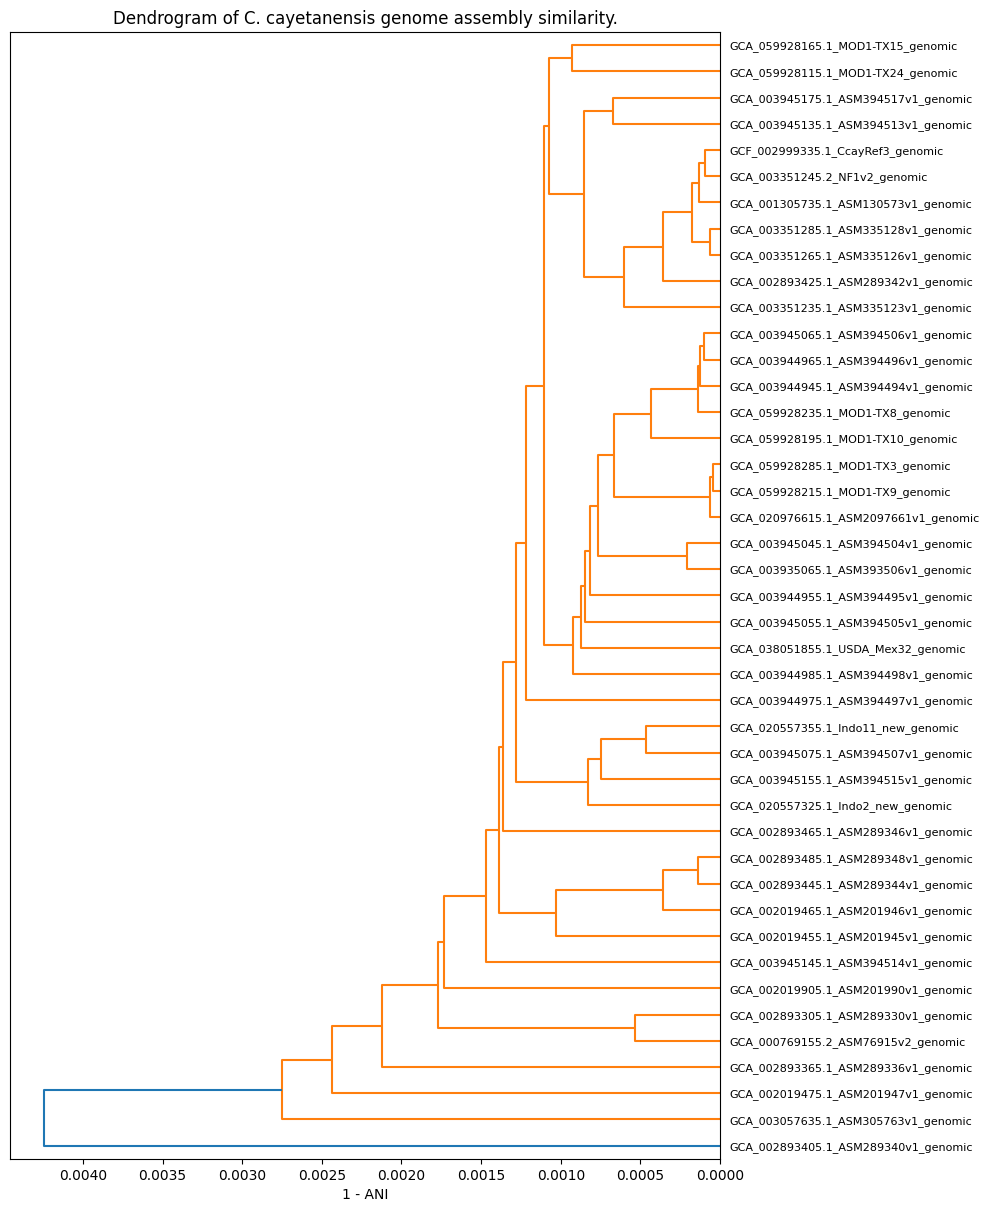

In [ ]:
sim = pd.read_csv("/content/ccay_jaccard.csv")
labels = list(sim.columns)
S = sim.values.astype(float)
S = (S + S.T) / 2
np.fill_diagonal(S, 1.0)

D = 1.0 - S
np.fill_diagonal(D, 0.0)
D[D < 0] = 0.0

Z = linkage(squareform(D, checks=False), method="average")

fig, ax = plt.subplots(figsize=(10, 12))
dendrogram(Z, labels=labels, orientation="left", ax=ax)
ax.set_xlabel("1 - ANI")
plt.tight_layout()
plt.title('Dendrogram of C. cayetanensis genome assembly similarity.')
plt.show()

As we can see, all genomes present a high degree of similarity.

In [ ]:
ccay_genome_summary.reset_index()

### **3.2 Clustering by year and geography.**

Standardize the data labels for year of sample collection and location.

Important note: sample collection date and location does not necessarily mean a CCay outbreak was occurring there at the time.

In [ ]:
ccay_genome_summary['Standardized Year'] = ccay_genome_summary['Assembly BioSample Collection date'].apply(
    lambda x: np.nan if pd.isna(x) or x in ['missing', 'not collected'] else str(x).split('-')[0]
)

display(ccay_genome_summary[['Assembly BioSample Collection date', 'Standardized Year']].head(10))

,Assembly BioSample Collection date,Standardized Year
0,2011-07,2011
1,2001-02,2001
2,2014,2014
3,1997,1997
4,2014,2014
5,1997,1997
6,2001,2001
9,2013,2013
10,2013,2013
11,2001,2001


In [ ]:
ccay_genome_summary['Standardized Location'] = ccay_genome_summary['Assembly BioSample Geographic location'].apply(
    lambda x: np.nan if pd.isna(x) or x in ['missing', 'not collected'] else str(x).split(':')[0]
)

display(ccay_genome_summary[['Assembly BioSample Geographic location', 'Standardized Location']])
print(ccay_genome_summary['Standardized Location'].value_counts())

,Assembly BioSample Geographic location,Standardized Location
0,China,China
1,USA: New York,USA
2,USA:Texas,USA
3,Guatemala,Guatemala
4,Indonesia,Indonesia
5,USA: Rhode Island,USA
6,China,China
9,USA:TX,USA
10,USA:FL,USA
11,USA:NY,USA


Standardized Location
USA          24
Nepal         6
Indonesia     5
Guatemala     3
China         2
Mexico        2
Canada        1
Name: count, dtype: int64


Plotting samples on a timeline.

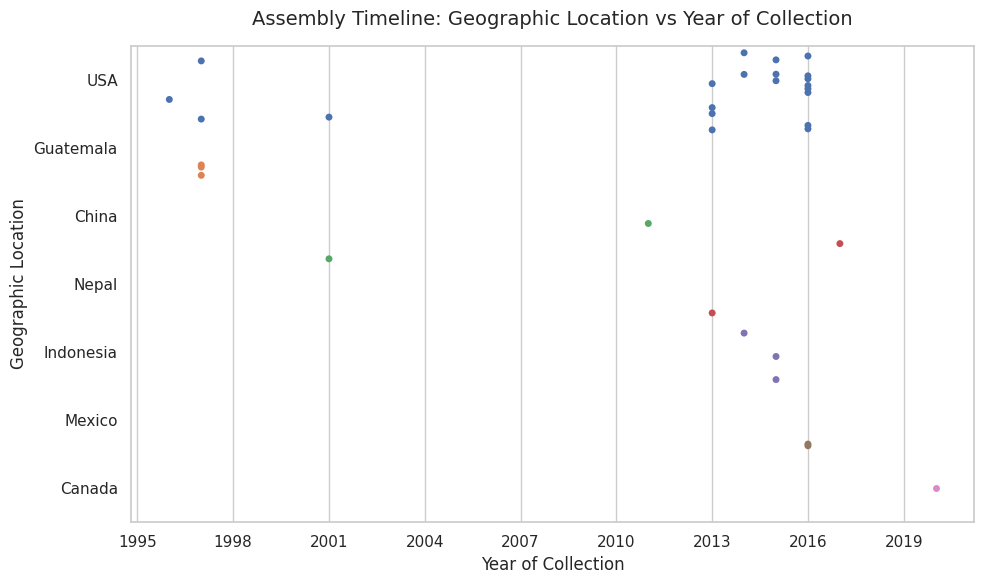

In [ ]:
# filter out missing records for both year and location
plot_df = ccay_genome_summary.dropna(subset=['Standardized Year', 'Standardized Location']).copy()

plot_df['Standardized Year'] = plot_df['Standardized Year'].astype(int)
plot_df = plot_df.sort_values(by='Standardized Year')

plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# use a stripplot to display the relationship without overlaps
sns.stripplot(
    data=plot_df,
    x="Standardized Year",
    y="Standardized Location",
    size=5,
    palette="deep",
    hue="Standardized Location",
    jitter=0.75,
    legend=False
)

plt.title("Assembly Timeline: Geographic Location vs Year of Collection", fontsize=14, pad=15)
plt.xlabel("Year of Collection", fontsize=12)
plt.ylabel("Geographic Location", fontsize=12)
plt.gca().xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

It's worth noting that the genomic assembly data collectded here is not necessarily representative of overall, global *C. cayetanensis* populations. In fact, it's not even representative of all the genomic information we *have*. (Notice a few genomes are missing from this visualization).

All we can do here is ensure there is no contamination and rank the genes of interest by conservation across all available genomes.

## **4. Liftoff annotation transfer**

With Liftoff, our goal is to lift the annotations from reference assembly `CCayRef3` to all the other remaining ones.

Liftover produces GFF3 annotation files, which we can then use to compare the same gene/protein across all assemblies. We can also drop the genomes with poor liftover completeness from our analysis.

In [ ]:
! curl -L https://github.com/lh3/minimap2/releases/download/v2.31/minimap2-2.31_x64-linux.tar.bz2 | tar -jxvf -
! ln -s /content/minimap2-2.31_x64-linux/minimap2 /usr/local/bin/minimap2
! minimap2

In [ ]:
! pip cache purge
! pip install liftoff --no-deps
! pip install pyfaidx pysam parasail gffutils networkx biopython numpy interlap ujson
! liftoff -h

In [ ]:
! mkdir liftoff_output
#! liftoff -g /content/ncbi_dataset/data/GCF_002999335.1/genomic.gff /content/ncbi_dataset/data/GCA_059928285.1/GCA_059928285.1_MOD1-TX3_genomic.fna /content/ncbi_dataset/data/GCF_002999335.1/GCF_002999335.1_CcayRef3_genomic.fna -o /content/liftoff_output/test.gff3 -exclude_partial

In [ ]:
GFF3 = Path("/content/drive/MyDrive/liftoff_output")
GFF3.mkdir(exist_ok=True)
TMP = Path("/content/intermediate_files/")
TMP.mkdir(exist_ok=True)
ref_gff = '/content/ncbi_dataset/data/GCF_002999335.1/genomic.gff'
ref_fna = '/content/ncbi_dataset/data/GCF_002999335.1/GCF_002999335.1_CcayRef3_genomic.fna'

# We will use 1 or 2 threads to prevent high parallel memory overhead causing OOM crashes
SAFE_CPU_COUNT = 1

for target_fna in tqdm(hq_fna_files):
    acc = target_fna.parent.name
    out = GFF3 / f"{acc}.gff"

    if out.exists():
        print(f"{out} found. Skipping...")
        continue
    if target_fna == ref_fna:
        continue

    print(f"Processing {acc}...")

    # clear any residual tmp files
    acc_tmp = TMP / acc
    shutil.rmtree(acc_tmp, ignore_errors=True)

    cmd = [
        "liftoff",
        "-g", str(ref_gff),
        "-o", str(out),
        "-u", f"{GFF3}/{acc}.unmapped.txt",
        "-dir", str(acc_tmp),
        "-p", str(SAFE_CPU_COUNT),
        "-flank", "0.1",
        str(target_fna), str(ref_fna),
    ]

    # run liftoff as a clean external process
    res = subprocess.run(cmd, capture_output=True, text=True)
    if res.returncode != 0:
        print(f"Error processing {acc}: {res.stderr[-500:]}")

    # clean up intermediate folder database
    shutil.rmtree(acc_tmp, ignore_errors=True)
    gc.collect()

print(len(list(GFF3.glob('*.gff')))), "liftoffs completed"

  0%|          | 0/43 [00:00<?, ?it/s]

/content/drive/MyDrive/liftoff_output/GCA_000769155.2.gff found. Skipping...
/content/drive/MyDrive/liftoff_output/GCA_001305735.1.gff found. Skipping...
/content/drive/MyDrive/liftoff_output/GCA_002019455.1.gff found. Skipping...
/content/drive/MyDrive/liftoff_output/GCA_002019465.1.gff found. Skipping...
/content/drive/MyDrive/liftoff_output/GCA_002019475.1.gff found. Skipping...
/content/drive/MyDrive/liftoff_output/GCA_002019905.1.gff found. Skipping...
/content/drive/MyDrive/liftoff_output/GCA_002893305.1.gff found. Skipping...
/content/drive/MyDrive/liftoff_output/GCA_002893365.1.gff found. Skipping...
/content/drive/MyDrive/liftoff_output/GCA_002893405.1.gff found. Skipping...
/content/drive/MyDrive/liftoff_output/GCA_002893425.1.gff found. Skipping...
/content/drive/MyDrive/liftoff_output/GCA_002893445.1.gff found. Skipping...
/content/drive/MyDrive/liftoff_output/GCA_002893465.1.gff found. Skipping...
/content/drive/MyDrive/liftoff_output/GCA_002893485.1.gff found. Skipping...

(None, 'liftoffs completed')

In [ ]:
def parse_attrs(field: str) -> dict:
    out = {}
    for kv in field.rstrip(";").split(";"):
        if "=" in kv:
            k, v = kv.split("=", 1)
            out[k.strip()] = v.strip()
    return out

def tobool(v):
    return {"True": True, "False": False}.get(v)

def parse_gff(path: Path, acc: str) -> list[dict]:
    genes, mrnas = {}, {}
    with open(path) as fh:
        for line in fh:
            if line.startswith("#"):
                continue
            f = line.rstrip("\n").split("\t")
            if len(f) < 9:
                continue
            ftype, attrs = f[2], parse_attrs(f[8])
            if ftype == "gene":
                gid = attrs.get("ID")
                genes[gid] = {
                    "gene_id": gid,
                    "seqid": f[0],
                    "start": int(f[3]),
                    "end": int(f[4]),
                    "coverage": float(attrs["coverage"]) if "coverage" in attrs else None,
                    "sequence_ID": float(attrs["sequence_ID"]) if "sequence_ID" in attrs else None,
                    "extra_copy_number": attrs.get("extra_copy_number"),
                    "partial_mapping": tobool(attrs.get("partial_mapping")) or False,
                    "low_identity": tobool(attrs.get("low_identity")) or False,
                }
            elif ftype in ("mRNA", "transcript"):
                parent = attrs.get("Parent")
                mrnas.setdefault(parent, []).append({
                    "valid_ORF": tobool(attrs.get("valid_ORF")),
                    "matches_ref_protein": tobool(attrs.get("matches_ref_protein")),
                    "missing_start_codon": tobool(attrs.get("missing_start_codon")),
                    "missing_stop_codon": tobool(attrs.get("missing_stop_codon")),
                    "inframe_stop_codon": tobool(attrs.get("inframe_stop_codon")),
                })

    rows = []
    for gid, g in genes.items():
        tx = mrnas.get(gid, [])
        g = {**g, "accession": acc, "lifted": True, "n_tx": len(tx)}
        if tx:
            g["valid_ORF"] = any(t["valid_ORF"] for t in tx)
            g["matches_ref_protein"] = any(t["matches_ref_protein"] for t in tx)
            for k in ("missing_start_codon", "missing_stop_codon", "inframe_stop_codon"):
                g[k] = any(t[k] for t in tx)
        rows.append(g)
    return rows

rows = []
for gff in sorted(GFF3.glob("*.gff")):
    acc = gff.stem
    rows += parse_gff(gff, acc)

long = pd.DataFrame(rows)
print(long.shape, long.accession.nunique(), "genomes")

(253517, 17) 43 genomes


In [ ]:
! awk -F'\t' '$3=="gene"' {REF_GFF} | grep -o 'ID=[^;]*' | sed 's/ID=//' > /content/ref_gene_ids.txt

Add the unmapped genes as explicit rows.

In [ ]:
ref_genes = set(pd.read_csv("/content/ref_gene_ids.txt", header=None)[0])

missing = []
for unm in sorted(GFF3.glob("*.unmapped.txt")):
    acc = unm.name.replace(".unmapped.txt", "")
    for gid in unm.read_text().split():
        missing.append({"gene_id": gid, "accession": acc, "lifted": False})

long = pd.concat([long, pd.DataFrame(missing)], ignore_index=True)
long["lifted"] = long.lifted.fillna(False)
print(long.shape)

(255420, 17)


Summarize data.

In [ ]:
n_gen = long.accession.nunique()

per_gene = long.groupby("gene_id").agg(
    n_lifted=("lifted", "sum"),
    n_valid_ORF=("valid_ORF", lambda s: s.fillna(False).sum()),
    n_matches_ref=("matches_ref_protein", lambda s: s.fillna(False).sum()),
    mean_cov=("coverage", "mean"),
    mean_seqid=("sequence_ID", "mean"),
).reset_index()
per_gene["lift_rate"] = per_gene.n_lifted / n_gen
per_gene["usable_rate"] = per_gene.n_valid_ORF / n_gen

per_genome = long.groupby("accession").agg(
    n_lifted=("lifted", "sum"),
    n_valid_ORF=("valid_ORF", lambda s: s.fillna(False).sum()),
    mean_cov=("coverage", "mean"),
).reset_index()
per_genome["lift_rate"] = per_genome.n_lifted / len(ref_genes)

long.to_parquet("/content/drive/MyDrive/lift_long.parquet")
per_gene.to_csv("/content/drive/MyDrive/lift_per_gene.csv", index=False)
per_genome.to_csv("/content/drive/MyDrive/lift_per_genome.csv", index=False)

/tmp/ipython-input-68-526185463.py:5: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  n_valid_ORF=("valid_ORF", lambda s: s.fillna(False).sum()),
/tmp/ipython-input-68-526185463.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  n_matches_ref=("matches_ref_protein", lambda s: s.fillna(False).sum()),
/tmp/ipython-input-68-526185463.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_opt

In [ ]:
ccay_genome_summary.to_csv('/content/drive/MyDrive/ccay_genome_summary.tsv', sep='\t', index=False)